[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tu_usuario/mecanismos-four-bars/blob/main/ex2_3_coupler_path_colored.ipynb)

# Example 2.3 — Coupler Path Colored by Crank Angle

**Chapter 2: Kinematic Analysis of the Four Bar Mechanism**  
Book: *Synthesis of Four-Bar Mechanisms with Genetic Algorithms and Neural Networks*

---

## Statement

For the mechanism with **a = 55 mm**, **b = 110 mm**, **c = 70 mm**, **d = 95 mm**,  
coupler point **p = 35 mm**, angular offset **δ = 45°**,  
plot the coupler curve **coloring** each point according to the value of θ₂  
to display the speed of the curve.

---

## Theoretical Foundation

The coordinates of the coupler point P are:

$$P_x = a\cos\theta_2 + p\cos(\theta_3 + ̔)$$
$$P_y = a\sin\theta_2 + p\sin(\theta_3 + ̔)$$

where **p** is the distance from the point P to the joint A measured along the coupler AB,  
and **δ** is the angle formed by AP with the coupler link AB.  
The color of each point represents the angle θ₂ at that instant.

In [1]:
from numpy import *
import matplotlib.pyplot as plt
import matplotlib.cm as cm

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'axes.grid': True,
    'grid.alpha': 0.35,
})

## Solution: Calculation of the Coupling Curve

In [2]:
def coupler_curve(a, b, c, d, p, delta_deg):
    """Calculates the coupler curve of the four-bar mechanism.
    Returns (Px, Py, angles_degrees)."""
    delta = radians(delta_deg)
    th2 = linspace(0, 2*pi, 360)

    K1 = d/a; K2 = d/c; K3 = (a**2 - b**2 + c**2 + d**2) / (2*a*c)

    A = cos(th2) - K1 - K2*cos(th2) + K3
    B = -2*sin(th2)
    C = K1 - (K2 + 1)*cos(th2) + K3

    disc = B**2 - 4*A*C
    th4 = where(disc >= 0, 2*arctan2(-B - sqrt(maximum(disc, 0)), 2*A), nan)

    K4 = d/b; K5 = (c**2 - d**2 - a**2 - b**2) / (2*a*b)
    A2 = cos(th2) - K1 + K4*cos(th2) + K5
    B2 = -2*sin(th2)
    C2 = K1 + (K4 - 1)*cos(th2) + K5

    disc2 = B2**2 - 4*A2*C2
    th3 = where(disc >= 0, 2*arctan2(-B2 - sqrt(maximum(disc2, 0)), 2*A2), nan)

    Px = a*cos(th2) + p*cos(th3 + delta)
    Py = a*sin(th2) + p*sin(th3 + delta)

    return Px, Py, degrees(th2)


# Mechanism parameters
a, b, c, d = 55., 110., 70., 95.
p_dist = 35.
delta = 45.

Px, Py, ang = coupler_curve(a, b, c, d, p_dist, delta)
validos = isfinite(Px)

print(f"Valid points: {validos.sum()}")
for q, (lo, hi) in enumerate([(0, 90), (90, 180), (180, 270), (270, 360)], 1):
    mask = validos & (ang >= lo) & (ang < hi)
    if mask.any():
        longitud = sum(sqrt(diff(Px[mask])**2 + diff(Py[mask])**2))
        print(f"  Quadrant {q} ({lo}°–{hi}°): {mask.sum()} pts, "
              f"arc length ≈ {longitud:.1f} mm")

Valid points: 360
  Quadrant 1 (0°–90°): 90 pts, arc length ≈ 89.6 mm
  Quadrant 2 (90°–180°): 90 pts, arc length ≈ 87.8 mm
  Quadrant 3 (180°–270°): 90 pts, arc length ≈ 70.8 mm
  Quadrant 4 (270°–360°): 89 pts, arc length ≈ 106.5 mm


## Figure 2.3 — Coupler Curve Colored by ̸₂

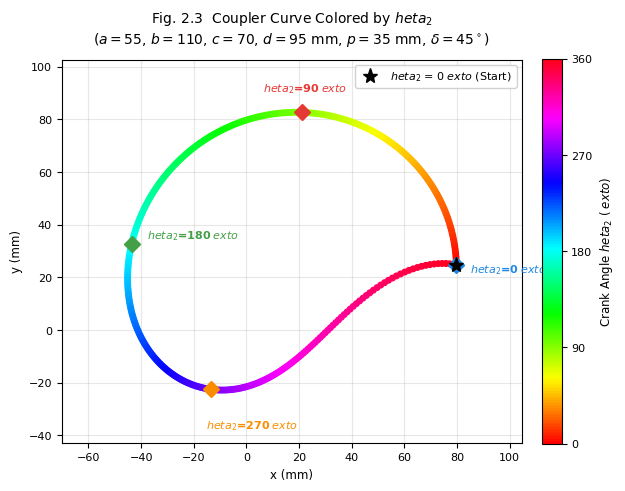

In [9]:
import os
import glob

# Dynamic notebook name retrieval with fallback as requested
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "fig_2_3_coupler_trajectory_colored"
except Exception:
    notebook_name = "fig_2_3_coupler_trajectory_colored"

# Configure Springer standard styles and editable vector text
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'font.size': 8,
    'axes.titlesize': 10,
    'axes.labelsize': 8.5,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

fig, ax = plt.subplots(figsize=(6.5, 5))

# Scatter plot colored by theta_2
sc = ax.scatter(Px[validos], Py[validos],
                c=ang[validos], cmap='hsv',
                s=16, vmin=0, vmax=360, zorder=4)

# Colorbar styling - Using raw string with standard LaTeX degree symbol
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cb.set_label(r'Crank Angle $	heta_2$ ($^	ext{o}$)', fontsize=8.5)
cb.set_ticks([0, 90, 180, 270, 360])
cb.ax.tick_params(labelsize=8)

# Mark standard positions (0, 90, 180, 270) with safety offsets to prevent overlap
colores_vis = ['#1E88E5', '#E53935', '#43A047', '#FB8C00']
offsets = {
    0: (5, -3),
    90: (-15, 8),
    180: (6, 2),
    270: (-2, -15)
}

for ang_vis, col in zip([0, 90, 180, 270], colores_vis):
    idx = argmin(abs(ang - ang_vis))
    ax.plot(Px[idx], Py[idx], 'D', color=col, ms=8, zorder=5)
    ox, oy = offsets.get(ang_vis, (4, 3))
    # Escaped curly braces for .format/f-string compatibility in LaTeX
    ax.annotate(rf'$	heta_2$={ang_vis}$^	ext{{o}}$',
                xy=(Px[idx], Py[idx]),
                xytext=(Px[idx] + ox, Py[idx] + oy),
                fontsize=8, color=col, fontweight='bold',
                zorder=6)

# Starting point marker
ax.plot(Px[validos][0], Py[validos][0], '*',
        color='k', ms=11, zorder=7, label=r'$	heta_2$ = 0$^	ext{o}$ (Start)')

ax.set_aspect('equal')
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')

# Constructing title string safely with double backslashes to completely avoid escape warnings
title_text = r'Fig. 2.3  Coupler Curve Colored by $	heta_2$' + '\n' + f'($a={a:.0f}$, $b={b:.0f}$, $c={c:.0f}$, $d={d:.0f}$ mm, $p={p_dist:.0f}$ mm, $\\delta={delta:.0f}^\\circ$)'
ax.set_title(title_text, pad=12)

# Expand axis boundaries slightly for clear annotations
ax.set_xlim(Px[validos].min() - 25, Px[validos].max() + 25)
ax.set_ylim(Py[validos].min() - 20, Py[validos].max() + 20)

ax.legend(loc='upper right', frameon=True, framealpha=0.9)

# Double Export format as required
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

## Exploration: Effect of ̴ Offset on Curve Shape

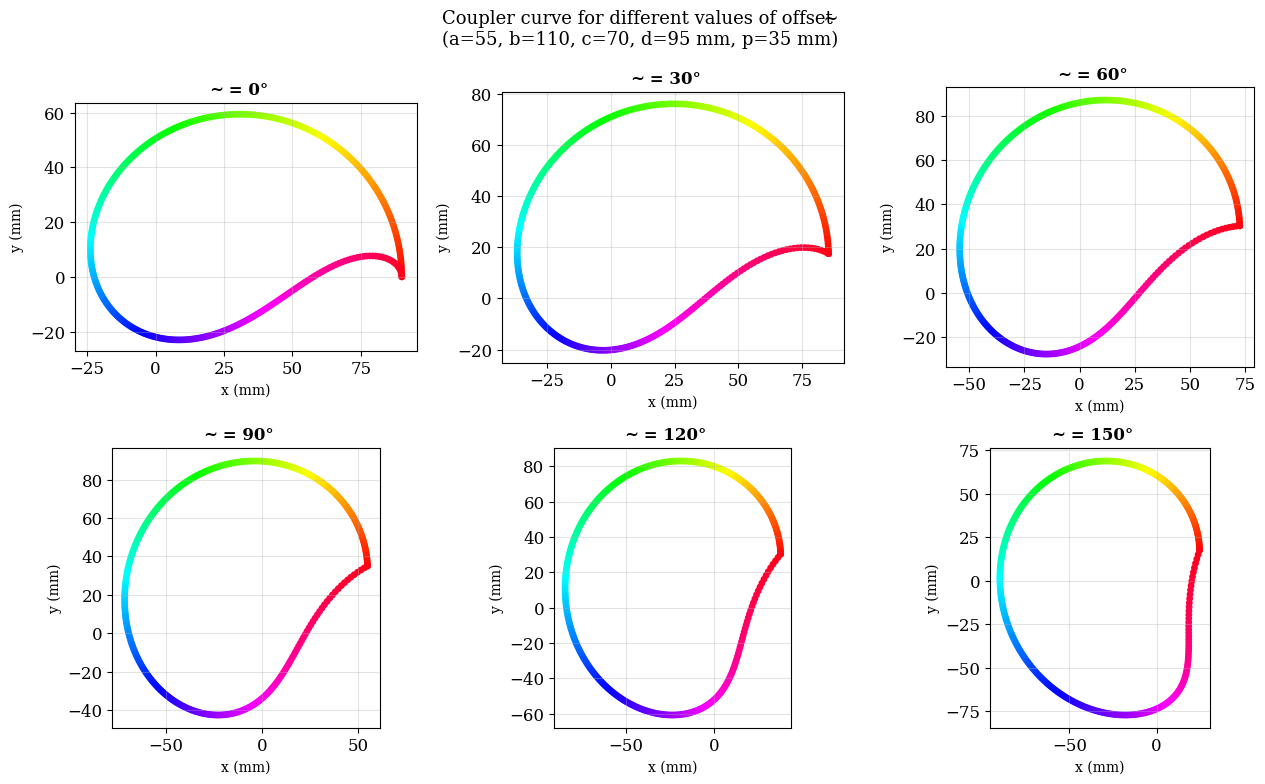


Total arc lengths per value of ̴:
  ̴ = 0°: total length ≈ 319.3 mm
  ̴ = 30°: total length ≈ 344.1 mm
  ̴ = 60°: total length ≈ 373.2 mm
  ̴ = 90°: total length ≈ 398.5 mm
  ̴ = 120°: total length ≈ 414.4 mm
  ̴ = 150°: total length ≈ 418.1 mm


In [4]:
# Compare curves for different values of ̴
deltas = [0., 30., 60., 90., 120., 150.]
cmap = plt.get_cmap('tab10')

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for i, delta_v in enumerate(deltas):
    Px_d, Py_d, ang_d = coupler_curve(a, b, c, d, p_dist, delta_v)
    val = isfinite(Px_d)
    sc = axes[i].scatter(Px_d[val], Py_d[val],
                         c=ang_d[val], cmap='hsv',
                         s=15, vmin=0, vmax=360)
    axes[i].set_aspect('equal')
    axes[i].set_title(f'̴ = {delta_v:.0f}°', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('x (mm)', fontsize=10)
    axes[i].set_ylabel('y (mm)', fontsize=10)

plt.suptitle('Coupler curve for different values of offset ̴\n'
             f'(a={a:.0f}, b={b:.0f}, c={c:.0f}, d={d:.0f} mm, p={p_dist:.0f} mm)',
             fontsize=13)
plt.tight_layout()
plt.show()

print("\nTotal arc lengths per value of ̴:")
for delta_v in deltas:
    Px_d, Py_d, _ = coupler_curve(a, b, c, d, p_dist, delta_v)
    val = isfinite(Px_d)
    if val.sum() > 1:
        lng = sum(sqrt(diff(Px_d[val])**2 + diff(Py_d[val])**2))
        print(f"  ̴ = {delta_v:.0f}°: total length ≈ {lng:.1f} mm")